# KNN (K Nearest Neighbors)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import Model
from sklearn.neighbors import KNeighborsClassifier
# Train Test
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
# Metrics
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [2]:
df = pd.read_csv('Dataset/student.csv')
df.head(2)

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,higher education,higher education,at_home,teacher,...,very good,medium,high,very low,very low,good,6,5,6,6
1,GP,F,17,U,GT3,T,primary education (4th grade),primary education (4th grade),at_home,other,...,excellent,medium,medium,very low,very low,good,4,5,5,6


## Feature Engineering

In [3]:
df['G3'].sort_values(ascending=False).unique()

array([20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10,  9,  8,  7,  6,  5,  4,
        0])

In [4]:
def convertMarks(marks):
    if marks >= 15 and marks <= 20:
        return 'A'
    elif marks >= 11 and marks < 15:
        return 'B'
    elif marks >= 7 and marks < 11:
        return 'C'
    else:
        return 'Fail'

In [5]:
df['Grade'] = df['G3'].apply(convertMarks)

In [6]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'Grade'],
      dtype='str')

In [7]:
columns = df[['Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup',
          'internet', 'freetime', 'goout', 'health', 'absences', 'G1', 'G2']]
columns.head(2)

,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,internet,freetime,goout,health,absences,G1,G2
0,higher education,higher education,15 to 30 min.,2 to 5 hours,0,yes,no,no,medium,high,good,6,5,6
1,primary education (4th grade),primary education (4th grade),<15 min.,2 to 5 hours,0,no,yes,yes,medium,medium,good,4,5,5


### Label Encoding

In [8]:
'''
    1. Sort Values by Ascending order.
    2. According to sort values, give them numbers from 0 to nth number.
'''

'\n    1. Sort Values by Ascending order.\n    2. According to sort values, give them numbers from 0 to nth number.\n'

In [9]:
# data = pd.Series(['AE', 'BE', 'CE', 'DE', 'AAE', 'DCE'])

le = LabelEncoder()
# data_df = le.fit_transform(data)
# le.inverse_transform(data_df)
# data_df

In [10]:
le_columns = ['schoolsup', 'famsup', 'internet']
def leConverter(dataframe, columns):
    for col in columns:
        dataframe[f'{col}_id'] = le.fit_transform(dataframe[col])
    print('Data converted successfully.')

In [11]:
leConverter(df, le_columns)

Data converted successfully.


In [12]:
df['Medu'].unique()

<ArrowStringArray>
[             'higher education', 'primary education (4th grade)',
           'secondary education',              '5th to 9th grade',
                          'none']
Length: 5, dtype: str

In [13]:
medu = {
    'none': 0,
    'primary education (4th grade)': 1,
    '5th to 9th grade': 2,
    'secondary education': 3,
    'higher education': 4
}

df['medu_id'] = df['Medu'].map(medu)

In [14]:
## Function for manual encoding
def manualEncoding(dataframe, col_name, *args):
    encoding_val = {}
    for idx, data in enumerate(args):
        encoding_val[data] = idx

    dataframe[f'{col_name}_id'] = dataframe[col_name].map(encoding_val)
    print(f'{col_name} data encoded.')

In [15]:
# Fedu
manualEncoding(df, 'Fedu', 'none', 'primary education (4th grade)', '5th to 9th grade', 'secondary education',
              'higher education')

Fedu data encoded.


In [16]:
# Travel Time
manualEncoding(df, 'traveltime', '<15 min.', '15 to 30 min.', '30 min. to 1 hour', '>1 hour')

traveltime data encoded.


In [17]:
# Study Time
manualEncoding(df, 'studytime', '<2 hours', '2 to 5 hours', '5 to 10 hours', '>10 hours')

studytime data encoded.


In [18]:
# Free time and Go Out
data = ['freetime', 'goout']
for col in data:
    manualEncoding(df, col, 'very low', 'low', 'medium', 'high', 'very high')

freetime data encoded.
goout data encoded.


In [19]:
manualEncoding(df, 'health', 'very bad', 'bad', 'good', 'very good', 'excellent')

health data encoded.


In [20]:
manualEncoding(df, 'Grade', 'Fail', 'C', 'B', 'A')

Grade data encoded.


## Feature and Target

In [21]:
features = ['medu_id', 'Fedu_id', 'traveltime_id', 'studytime_id', 'failures', 'schoolsup_id',
           'famsup_id', 'internet_id', 'freetime_id', 'goout_id', 'health_id', 'absences', 'G1', 'G2']
target = 'Grade_id'

In [22]:
X = df[features]
Y = df[target]

## Train Test Split

In [23]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y
)

## Feature Scaling

In [24]:
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

## Elbow Method

In [25]:
k_range = range(1, 21)
error_rate = []
acc_score = []

for i in k_range:
    knn = KNeighborsClassifier(n_neighbors=i, n_jobs=1)
    knn.fit(X_train_scale, Y_train)
    knn_pred = knn.predict(X_test_scale)
    error_rate.append(np.mean(Y_test != knn_pred))
    acc_score.append(accuracy_score(Y_test, knn_pred))

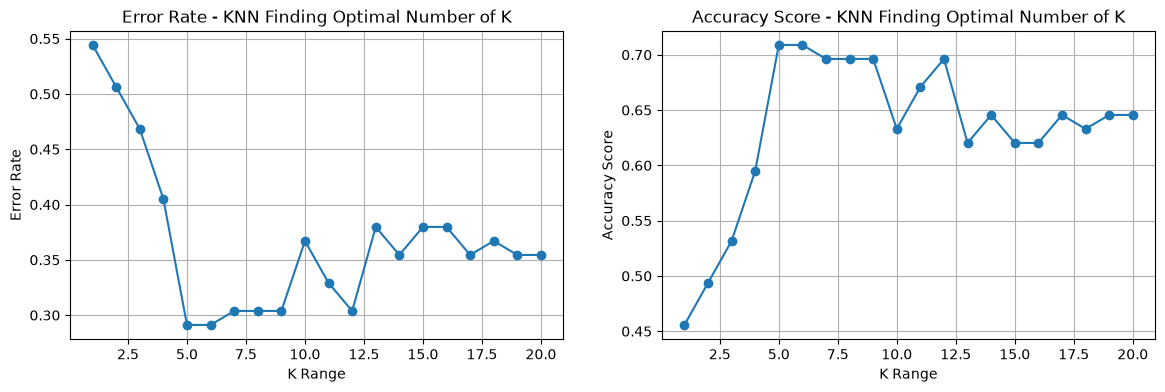

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax1 = axes[0]
ax1.plot(k_range, error_rate, marker='o')
ax1.set_xlabel('K Range')
ax1.set_ylabel('Error Rate')
ax1.set_title('Error Rate - KNN Finding Optimal Number of K')
ax1.grid()

ax2 = axes[1]
ax2.plot(k_range, acc_score, marker='o')
ax2.set_xlabel('K Range')
ax2.set_ylabel('Accuracy Score')
ax2.set_title('Accuracy Score - KNN Finding Optimal Number of K')
ax2.grid()

plt.show()

## Model Implementation

In [27]:
k = 5
model = KNeighborsClassifier(n_neighbors=k, n_jobs=1)
model.fit(X_train_scale, Y_train)
Y_pred = model.predict(X_test_scale)

## Metrics

In [28]:
cr = classification_report(Y_test, Y_pred)
cm = confusion_matrix(Y_test, Y_pred)

In [29]:
print(cr)

              precision    recall  f1-score   support

           0       0.67      0.50      0.57        12
           1       0.62      0.72      0.67        25
           2       0.74      0.74      0.74        27
           3       0.86      0.80      0.83        15

    accuracy                           0.71        79
   macro avg       0.72      0.69      0.70        79
weighted avg       0.71      0.71      0.71        79



In [30]:
print(cm)

[[ 6  6  0  0]
 [ 3 18  4  0]
 [ 0  5 20  2]
 [ 0  0  3 12]]


<Axes: >

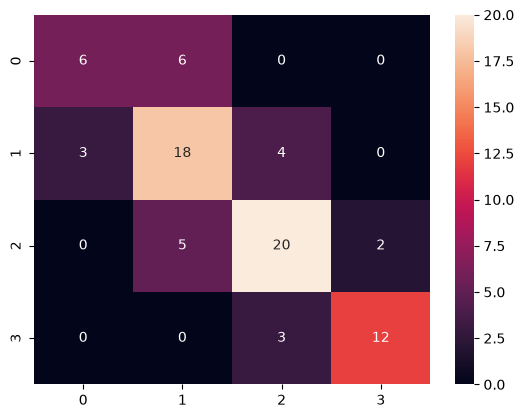

In [31]:
sns.heatmap(cm, annot=True)

## Cross Validation

In [32]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kfold_error_rate = []
kfold_acc_score = []

for i in k_range:
    kfold_knn = KNeighborsClassifier(n_neighbors=i, n_jobs=1)
    scores = cross_val_score(kfold_knn, X_train_scale, Y_train, cv=kfold, scoring='accuracy')

    kfold_error_rate.append(1 - scores.mean())
    kfold_acc_score.append(scores.mean())

best_k = k_range[np.argmax(kfold_acc_score)]
best_k

13

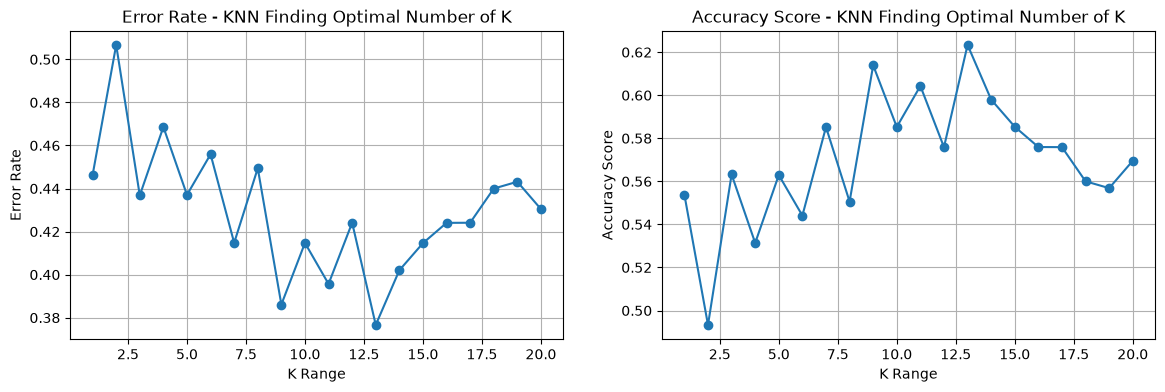

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

ax1 = axes[0]
ax1.plot(k_range, kfold_error_rate, marker='o')
ax1.set_xlabel('K Range')
ax1.set_ylabel('Error Rate')
ax1.set_title('Error Rate - KNN Finding Optimal Number of K')
ax1.grid()

ax2 = axes[1]
ax2.plot(k_range, kfold_acc_score, marker='o')
ax2.set_xlabel('K Range')
ax2.set_ylabel('Accuracy Score')
ax2.set_title('Accuracy Score - KNN Finding Optimal Number of K')
ax2.grid()

plt.show()

## Grid Search

In [34]:
'''
- euclidean -> continuous data + dense data,
- manhattan -> ordinal data
- euclidean + manhattan -> nominal data
'''
params = {
    'n_neighbors': list(range(1, 35)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

In [35]:
grid_cv = GridSearchCV(
    estimator = KNeighborsClassifier(),
    param_grid = params,
    cv = kfold,
    scoring = 'accuracy',
    n_jobs=1
)

In [36]:
grid_cv.fit(X_train_scale, Y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'metric': ['euclidean', 'manhattan'], 'n_neighbors': [1, 2, ...], 'weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

In [37]:
best_knn = grid_cv.best_estimator_
best_knn_pred = best_knn.predict(X_test_scale)

In [38]:
best_cm = confusion_matrix(Y_test, best_knn_pred)
best_cr = classification_report(Y_test, best_knn_pred)

In [39]:
print(best_cr)

              precision    recall  f1-score   support

           0       1.00      0.42      0.59        12
           1       0.68      0.84      0.75        25
           2       0.71      0.81      0.76        27
           3       0.92      0.73      0.81        15

    accuracy                           0.75        79
   macro avg       0.83      0.70      0.73        79
weighted avg       0.78      0.75      0.74        79



In [40]:
from sklearn.svm import SVC

In [62]:
svc_model = SVC(
    kernel = 'linear',
    C = 1
)

svc_model.fit(X_train_scale, Y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [63]:
svc_pred = svc_model.predict(X_test_scale)

In [64]:
svc_cr = classification_report(Y_test, svc_pred)
print(svc_cr)

              precision    recall  f1-score   support

           0       0.82      0.75      0.78        12
           1       0.79      0.88      0.83        25
           2       0.91      0.78      0.84        27
           3       0.82      0.93      0.88        15

    accuracy                           0.84        79
   macro avg       0.84      0.84      0.83        79
weighted avg       0.84      0.84      0.83        79

